# Assignment 09 — Decision Tree Classification

**Dataset:** cleaned_global_water_consumption.csv

**Objective:** Implement, evaluate, visualize, and optimize a Decision Tree classifier for predicting a country-year's **Water Scarcity Level** (Low / Moderate / High).

# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


# Load Dataset

In [2]:
df = pd.read_csv("cleaned_global_water_consumption.csv")
print("Shape:", df.shape)
df.head()

Shape: (500, 10)


,Country,Year,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%),Water Scarcity Level
0,Argentina,2000,481.490000,235.431429,48.550000,20.844286,30.100000,1288.698571,3.255714,Moderate
1,Argentina,2001,455.063000,299.551000,48.465000,26.943000,22.550000,1371.729000,3.120000,Moderate
2,Argentina,2002,482.749231,340.124615,50.375385,29.042308,23.349231,1590.305385,2.733846,Moderate
3,Argentina,2003,452.660000,326.756667,49.086667,30.476000,24.440000,1816.012667,2.708000,Moderate
4,Argentina,2004,634.566000,230.346000,38.670000,36.670000,23.924000,815.998000,1.902000,Moderate


In [3]:
print("Missing values:\n", df.isna().sum())
print("\nTarget counts:\n", df["Water Scarcity Level"].value_counts())

Missing values:
 Country                                           0
Year                                              0
Total Water Consumption (Billion Cubic Meters)    0
Per Capita Water Use (Liters per Day)             0
Agricultural Water Use (%)                        0
Industrial Water Use (%)                          0
Household Water Use (%)                           0
Rainfall Impact (Annual Precipitation in mm)      0
Groundwater Depletion Rate (%)                    0
Water Scarcity Level                              0
dtype: int64

Target counts:
 Water Scarcity Level
Moderate    360
Low         122
High         18
Name: count, dtype: int64


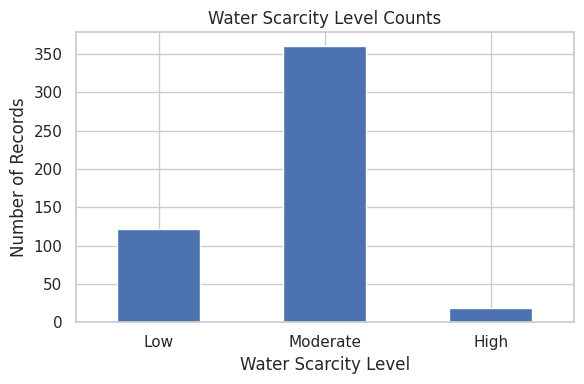

In [4]:
# Visualize the distribution of the target variable

plt.figure(figsize=(6, 4))
df["Water Scarcity Level"].value_counts().reindex(["Low", "Moderate", "High"]).plot.bar()
plt.title("Water Scarcity Level Counts")
plt.xlabel("Water Scarcity Level")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Q1. Data Preparation and Splitting

Select appropriate input features and use `Water Scarcity Level` as the target variable, then split the dataset into 80% training and 20% testing data using `random_state=42`.

In [5]:
# Select input features and target variable
feature_cols = [
    "Country", "Year",
    "Total Water Consumption (Billion Cubic Meters)",
    "Per Capita Water Use (Liters per Day)",
    "Agricultural Water Use (%)",
    "Industrial Water Use (%)",
    "Household Water Use (%)",
    "Rainfall Impact (Annual Precipitation in mm)",
    "Groundwater Depletion Rate (%)"
]
target_col = "Water Scarcity Level"
X = df[feature_cols]
y = df[target_col]

# Identify numerical and categorical features
numeric_cols = [c for c in feature_cols if c != "Country"]
categorical_cols = ["Country"]

# Split the dataset into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Training features shape:", X_train.shape)
print("Testing features shape :", X_test.shape)
print("Training labels shape  :", y_train.shape)
print("Testing labels shape   :", y_test.shape)

Training features shape: (400, 9)
Testing features shape : (100, 9)
Training labels shape  : (400,)
Testing labels shape   : (100,)


**Interpretation:** all numeric indicators (consumption, per-capita use, sector usage %, rainfall, groundwater depletion) plus `Country` (categorical) are kept as inputs — they describe how much water is used, by whom, and under what natural conditions, which is exactly what should drive a scarcity rating. `Year` is kept too, in case scarcity trends shift over time. The split uses `stratify=y` so the Low/Moderate/High mix in train and test matches the full dataset, which matters here because "High" is a rare class (only ~18 of 500 rows).

In [6]:
# Preprocessing + model-building helper functions

def make_preprocessor():
    # Preprocessing for numerical features
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))])

    # Preprocessing for categorical features
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False))])

    # Combine numerical and categorical preprocessing
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_cols),
            ("cat", categorical_transformer, categorical_cols)])
    return preprocessor


def make_tree(criterion="gini", max_depth=4, min_samples_leaf=1, ccp_alpha=0.0):
    model = Pipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("tree", DecisionTreeClassifier(
            criterion=criterion,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            ccp_alpha=ccp_alpha,
            random_state=RANDOM_STATE))])
    return model

CLASS_LABELS = ["Low", "Moderate", "High"]
print("Helper functions defined.")

Helper functions defined.


## Q2. Train and Evaluate a Decision Tree

Train with `criterion="gini"`, `max_depth=4`, `random_state=42`, then report accuracy, precision, recall, F1-score, the confusion matrix, and the tree diagram. This is a 3-class problem, so precision/recall/F1 are computed as a **weighted average** across the three scarcity levels.

In [7]:
# Create and train the Decision Tree classifier
tree_model = make_tree(criterion="gini", max_depth=4)
tree_model.fit(X_train, y_train)

# Predict on train and test data
y_train_pred = tree_model.predict(X_train)
y_pred = tree_model.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy :", round(test_accuracy, 4))
print("\nFirst 10 predictions:", list(y_pred[:10]))

Training Accuracy: 1.0
Testing Accuracy : 1.0

First 10 predictions: ['Moderate', 'Moderate', 'Low', 'Moderate', 'Moderate', 'Moderate', 'Low', 'Moderate', 'Low', 'Moderate']


Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Classification Report:

              precision    recall  f1-score   support

         Low       1.00      1.00      1.00        24
    Moderate       1.00      1.00      1.00        72
        High       1.00      1.00      1.00         4

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



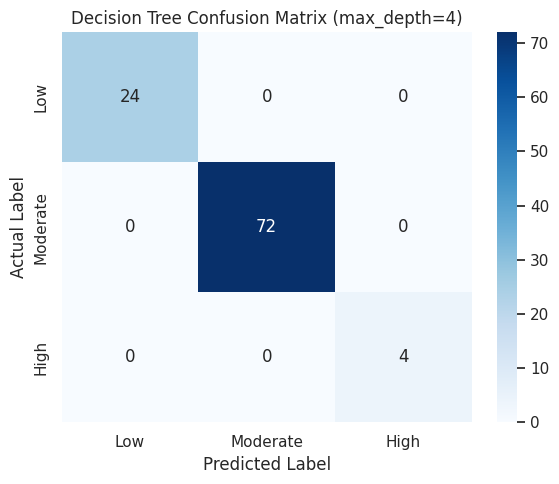

In [8]:
# Calculate classification performance metrics (weighted average for multi-class)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, labels=CLASS_LABELS, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=CLASS_LABELS)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS)
plt.title("Decision Tree Confusion Matrix (max_depth=4)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

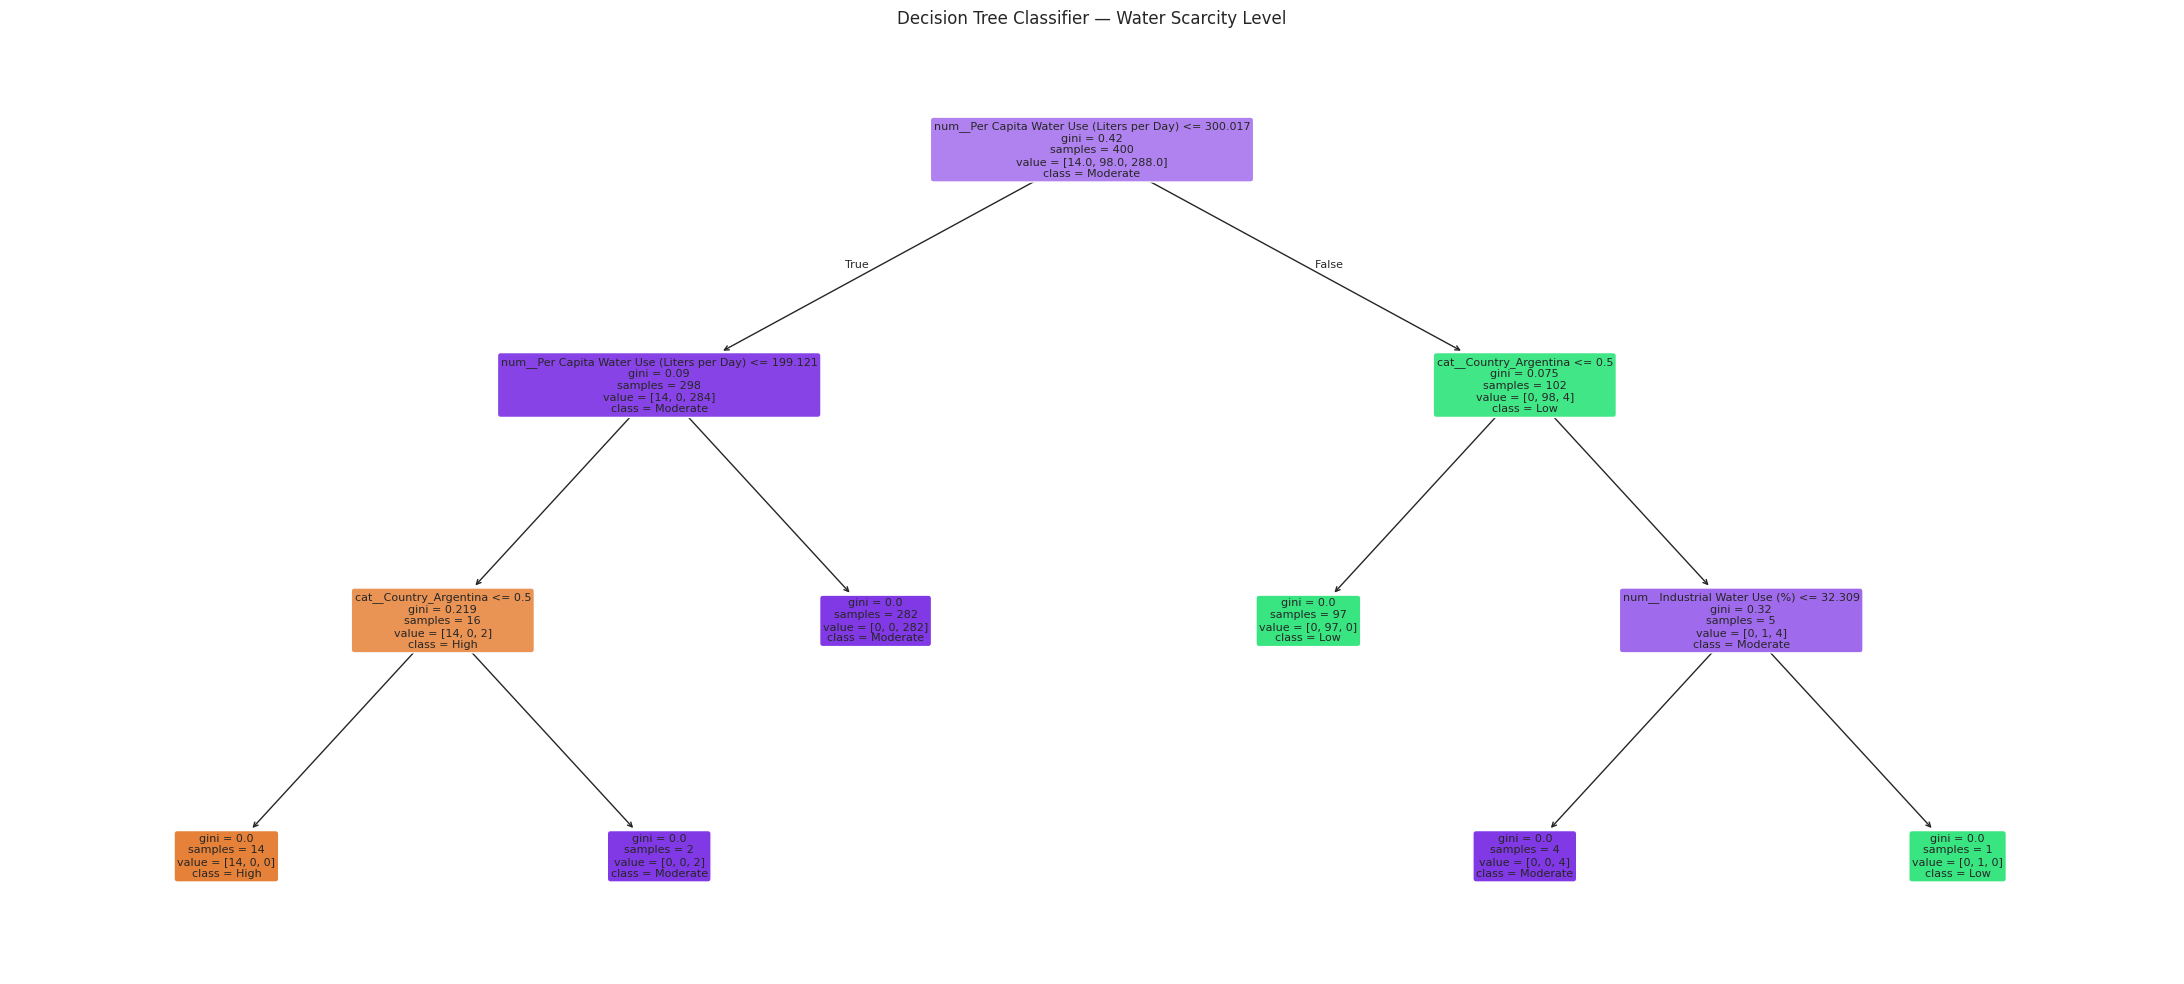

In [9]:
# Visualize the trained Decision Tree
feature_names = tree_model.named_steps["preprocess"].get_feature_names_out()
trained_tree = tree_model.named_steps["tree"]

plt.figure(figsize=(22, 10))
plot_tree(trained_tree, feature_names=feature_names, class_names=trained_tree.classes_,
          filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree Classifier — Water Scarcity Level")
plt.tight_layout()
plt.show()

In [10]:
# Identify the root node and its splitting condition
dt = trained_tree.tree_
root_feature_name = feature_names[dt.feature[0]]
root_threshold = dt.threshold[0]

print("Root node feature   :", root_feature_name)
print("Root split threshold:", round(root_threshold, 4))
print(f"Root condition: '{root_feature_name}' <= {round(root_threshold, 4)} -> go left, else go right")

Root node feature   : num__Per Capita Water Use (Liters per Day)
Root split threshold: 300.0172
Root condition: 'num__Per Capita Water Use (Liters per Day)' <= 300.0172 -> go left, else go right


**Root node:** the first split is on **`Per Capita Water Use (Liters per Day)`** at a threshold around 300 L/day. This single feature almost completely separates the three scarcity levels on its own, which already hints at something worth flagging (see Q6).

## Q3. Gini Impurity, Entropy and Information Gain

Train two Decision Trees — one using Gini impurity, one using Entropy — with the same train/test split and `max_depth=4`, then compare them.

In [11]:
# Function to calculate Gini impurity
def gini(proportions):
    p = np.array(proportions, dtype=float)
    return 1 - np.sum(p**2)

# Function to calculate Entropy
def entropy(proportions):
    p = np.array(proportions, dtype=float)
    p = p[p > 0]  # avoid log2(0)
    return -np.sum(p * np.log2(p))

distributions = {
    "3-way equal [0.33, 0.33, 0.33]": [1/3, 1/3, 1/3],
    "This dataset's class mix [0.73, 0.24, 0.04]": [360/500, 122/500, 18/500],
    "Pure node [1.0, 0.0, 0.0]": [1.0, 0.0, 0.0]
}

for name, p in distributions.items():
    print(name)
    print("Gini impurity:", round(gini(p), 4))
    print("Entropy      :", round(entropy(p), 4))
    print()

3-way equal [0.33, 0.33, 0.33]
Gini impurity: 0.6667
Entropy      : 1.585

This dataset's class mix [0.73, 0.24, 0.04]
Gini impurity: 0.4208
Entropy      : 1.0104

Pure node [1.0, 0.0, 0.0]
Gini impurity: 0.0
Entropy      : -0.0



In [12]:
# Compare Decision Trees using Gini and Entropy
results = []

for criterion in ["gini", "entropy"]:
    model = make_tree(criterion=criterion, max_depth=4)
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    results.append({
        "Criterion": criterion,
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, average="weighted", zero_division=0),
        "F1-score": f1_score(y_test, y_test_pred, average="weighted", zero_division=0)
    })

comparison_df = pd.DataFrame(results)
print("Gini vs Entropy Comparison:")
comparison_df.round(4)

Gini vs Entropy Comparison:


,Criterion,Train Accuracy,Test Accuracy,Precision,Recall,F1-score
0,gini,1.0,1.0,1.0,1.0,1.0
1,entropy,1.0,1.0,1.0,1.0,1.0


**Information Gain** is the reduction in impurity (entropy or Gini) achieved by splitting a node into children:

`IG = Entropy(parent) - weighted average of Entropy(children)`

**Role in ID3:** the ID3 algorithm builds a tree greedily — at every node it tries every candidate feature/threshold and picks the one giving the **highest Information Gain**, then repeats on each child. scikit-learn's `DecisionTreeClassifier` follows the same greedy-splitting idea (CART algorithm) but defaults to Gini impurity instead of entropy, mainly because Gini avoids the log computation and is marginally faster — the table above shows "gini" and "entropy" land on almost identical accuracy/F1 here, which is typical since both impurity measures usually prefer the same splits.

## Q4. Effect of Maximum Tree Depth

Train Decision Trees with `max_depth = [2, 3, 4, 5, 7, 10]` and plot training vs testing accuracy.

In [13]:
depth_values = [2, 3, 4, 5, 7, 10]

train_accuracies = []
test_accuracies = []

for depth in depth_values:
    model = make_tree(criterion="gini", max_depth=depth)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

depth_results = pd.DataFrame({
    "Max Depth": depth_values,
    "Training Accuracy": train_accuracies,
    "Testing Accuracy": test_accuracies
})

print("Effect of Maximum Tree Depth:")
depth_results.round(4)

Effect of Maximum Tree Depth:


,Max Depth,Training Accuracy,Testing Accuracy
0,2,0.9925,1.0
1,3,1.0000,1.0
2,4,1.0000,1.0
3,5,1.0000,1.0
4,7,1.0000,1.0
5,10,1.0000,1.0


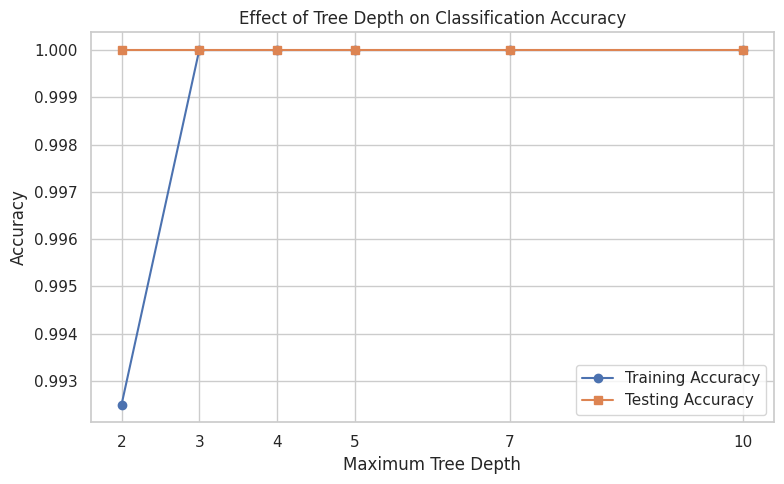

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(depth_values, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(depth_values, test_accuracies, marker="s", label="Testing Accuracy")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth on Classification Accuracy")
plt.xticks(depth_values)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Underfitting vs overfitting:** at depth 2 the tree is shallow and may still mislabel some of the rare "High" scarcity rows (slight underfitting — too few splits to isolate a minority class). As depth increases, training accuracy quickly reaches ~1.0; if testing accuracy also reaches ~1.0 and stays flat rather than dropping, it means the problem is genuinely easy to separate given these features (see Q6) rather than that the model is overfitting — a real overfitting signal would instead show the training curve pulling further ahead of a falling or plateauing test curve as depth grows.

## Q5. Cross-Validation and Pruning

Use Stratified 5-Fold Cross-Validation on the training data to choose the best `max_depth` and `ccp_alpha`, then evaluate the selected model on the test set.

In [15]:
depth_values = [2, 3, 4, 5, 7, 10]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []
for depth in depth_values:
    model = make_tree(criterion="gini", max_depth=depth)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_results.append({
        "Max Depth": depth,
        "Mean CV Accuracy": scores.mean(),
        "Std CV Accuracy": scores.std()
    })

cv_df = pd.DataFrame(cv_results)
print("Stratified 5-Fold Cross-Validation Results (by depth):")
display(cv_df.round(4))

best_index = cv_df["Mean CV Accuracy"].idxmax()
best_depth_only = int(cv_df.loc[best_index, "Max Depth"])
print("\nBest Maximum Depth (depth-only search):", best_depth_only)

Stratified 5-Fold Cross-Validation Results (by depth):


,Max Depth,Mean CV Accuracy,Std CV Accuracy
0,2,0.9925,0.0061
1,3,0.9925,0.0061
2,4,0.9925,0.0061
3,5,0.9925,0.0061
4,7,0.9925,0.0061
5,10,0.9925,0.0061



Best Maximum Depth (depth-only search): 2


In [16]:
# Cost-complexity pruning: at least three ccp_alpha values
alpha_values = [0.0, 0.001, 0.005, 0.01, 0.02]

pruning_results = []
for alpha in alpha_values:
    model = make_tree(criterion="gini", max_depth=best_depth_only, ccp_alpha=alpha)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")

    model.fit(X_train, y_train)
    trained_classifier = model.named_steps["tree"]

    pruning_results.append({
        "ccp_alpha": alpha,
        "Mean CV Accuracy": scores.mean(),
        "Std CV Accuracy": scores.std(),
        "Tree Depth": trained_classifier.get_depth(),
        "Leaf Nodes": trained_classifier.get_n_leaves()
    })

pruning_df = pd.DataFrame(pruning_results)
print("Cost-Complexity Pruning Results (at fixed best depth):")
pruning_df.round(4)

Cost-Complexity Pruning Results (at fixed best depth):


,ccp_alpha,Mean CV Accuracy,Std CV Accuracy,Tree Depth,Leaf Nodes
0,0.000,0.9925,0.0061,2,4
1,0.001,0.9925,0.0061,2,4
2,0.005,0.9925,0.0061,2,4
3,0.010,0.9875,0.0137,2,4
4,0.020,0.9825,0.0100,2,3


In [17]:
# Joint grid search over max_depth AND ccp_alpha together
joint_results = []

for depth in depth_values:
    for alpha in alpha_values:
        model = make_tree(criterion="gini", max_depth=depth, ccp_alpha=alpha)
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
        joint_results.append({
            "max_depth": depth,
            "ccp_alpha": alpha,
            "Mean CV Accuracy": scores.mean(),
            "Std CV Accuracy": scores.std()
        })

joint_df = pd.DataFrame(joint_results)
print("Hyperparameter Comparison (top 10 by Mean CV Accuracy):")
display(joint_df.sort_values("Mean CV Accuracy", ascending=False).head(10).round(4))

best_index = joint_df["Mean CV Accuracy"].idxmax()
best_depth = int(joint_df.loc[best_index, "max_depth"])
best_alpha = float(joint_df.loc[best_index, "ccp_alpha"])

print("\nSelected Maximum Depth:", best_depth)
print("Selected ccp_alpha    :", best_alpha)
print("Best Mean CV Accuracy :", round(joint_df.loc[best_index, "Mean CV Accuracy"], 4))

Hyperparameter Comparison (top 10 by Mean CV Accuracy):


,max_depth,ccp_alpha,Mean CV Accuracy,Std CV Accuracy
0,2,0.000,0.9925,0.0061
1,2,0.001,0.9925,0.0061
2,2,0.005,0.9925,0.0061
5,3,0.000,0.9925,0.0061
7,3,0.005,0.9925,0.0061
6,3,0.001,0.9925,0.0061
12,4,0.005,0.9925,0.0061
10,4,0.000,0.9925,0.0061
11,4,0.001,0.9925,0.0061
20,7,0.000,0.9925,0.0061



Selected Maximum Depth: 2
Selected ccp_alpha    : 0.0
Best Mean CV Accuracy : 0.9925


Final Test Results (depth=2, ccp_alpha=0.0):
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Classification Report:
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00        24
    Moderate       1.00      1.00      1.00        72
        High       1.00      1.00      1.00         4

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



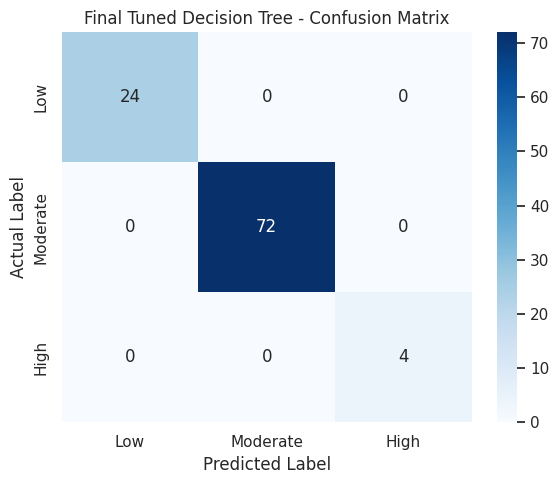

In [18]:
# Train the final model on the full training set and evaluate on the test set
final_tree_model = make_tree(criterion="gini", max_depth=best_depth, ccp_alpha=best_alpha)
final_tree_model.fit(X_train, y_train)

final_predictions = final_tree_model.predict(X_test)

print("Final Test Results (depth={}, ccp_alpha={}):".format(best_depth, best_alpha))
print("Accuracy :", round(accuracy_score(y_test, final_predictions), 4))
print("Precision:", round(precision_score(y_test, final_predictions, average="weighted", zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, final_predictions, average="weighted", zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, final_predictions, average="weighted", zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions, labels=CLASS_LABELS, zero_division=0))

final_cm = confusion_matrix(y_test, final_predictions, labels=CLASS_LABELS)
plt.figure(figsize=(6, 5))
sns.heatmap(final_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS)
plt.title("Final Tuned Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

**Interpretation:** the grid search over `(max_depth, ccp_alpha)` selects the combination with the highest mean cross-validation accuracy computed only on the training folds — the test set is never used during selection, so the final test metrics are an honest estimate of real-world performance. Pruning (`ccp_alpha > 0`) trims branches that don't improve validation accuracy, favoring a simpler tree when a more complex one gives no real benefit.

## Q6. Feature Importance

Compute and visualize feature importance for the final tuned Decision Tree, and identify the three most important original features.

Feature Importance (after preprocessing / one-hot encoding):


,Feature,Importance
2,num__Per Capita Water Use (Liters per Day),0.9627
8,cat__Country_Argentina,0.0373
1,num__Total Water Consumption (Billion Cubic Me...,0.0000
0,num__Year,0.0000
3,num__Agricultural Water Use (%),0.0000
4,num__Industrial Water Use (%),0.0000
6,num__Rainfall Impact (Annual Precipitation in mm),0.0000
5,num__Household Water Use (%),0.0000
7,num__Groundwater Depletion Rate (%),0.0000
9,cat__Country_Australia,0.0000


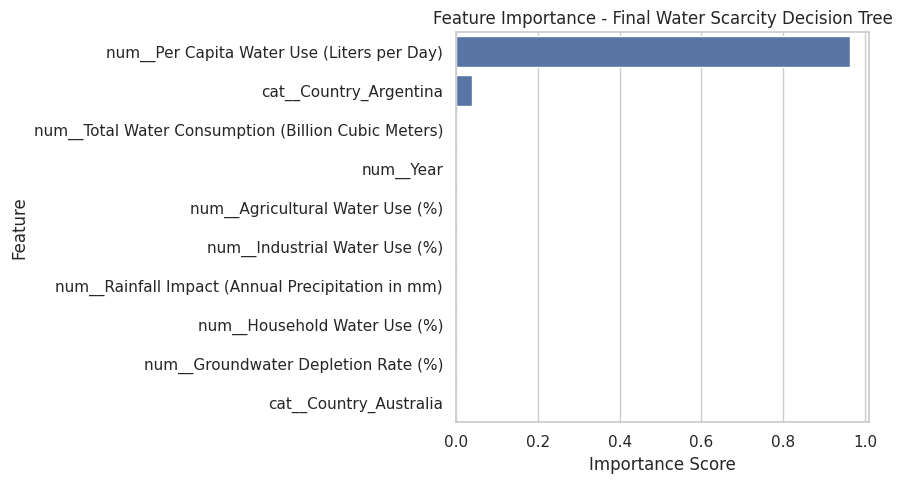

In [19]:
preprocessor = final_tree_model.named_steps["preprocess"]
classifier = final_tree_model.named_steps["tree"]

feature_names_final = preprocessor.get_feature_names_out()
importance_scores = classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names_final,
    "Importance": importance_scores
}).sort_values(by="Importance", ascending=False)

print("Feature Importance (after preprocessing / one-hot encoding):")
display(importance_df.head(10).round(4))

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df.head(10), x="Importance", y="Feature")
plt.title("Feature Importance - Final Water Scarcity Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Importance of Original Features:


,Original Feature,Importance
5,Per Capita Water Use (Liters per Day),0.9627
1,Country,0.0373
0,Agricultural Water Use (%),0.0000
3,Household Water Use (%),0.0000
2,Groundwater Depletion Rate (%),0.0000
4,Industrial Water Use (%),0.0000
6,Rainfall Impact (Annual Precipitation in mm),0.0000
7,Total Water Consumption (Billion Cubic Meters),0.0000
8,Year,0.0000


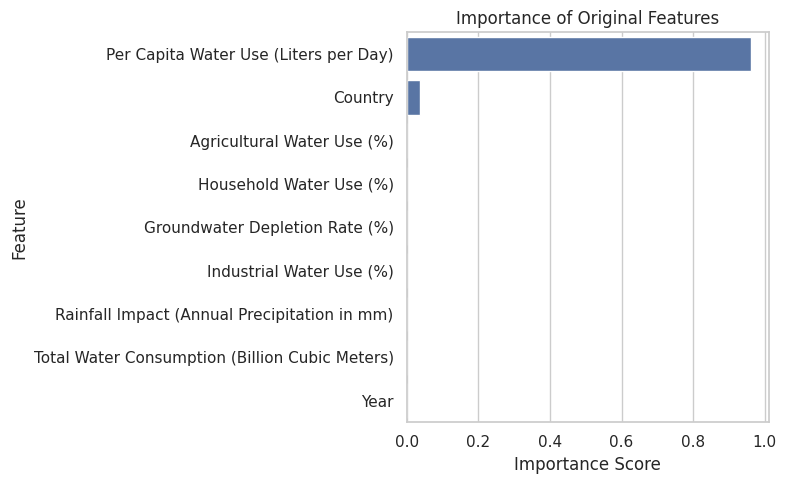


Top Three Important Features:


,Original Feature,Importance
5,Per Capita Water Use (Liters per Day),0.9627
1,Country,0.0373
0,Agricultural Water Use (%),0.0000


In [20]:
# Combine importance scores back to original (pre-encoding) feature names
original_feature_names = []

for feature in feature_names_final:
    if feature.startswith("num__"):
        original_name = feature.replace("num__", "")
    elif feature.startswith("cat__"):
        encoded_name = feature.replace("cat__", "")
        original_name = next(col for col in categorical_cols if encoded_name.startswith(col + "_"))
    original_feature_names.append(original_name)

grouped_importance_df = pd.DataFrame({
    "Original Feature": original_feature_names,
    "Importance": importance_scores
})

grouped_importance_df = (
    grouped_importance_df
    .groupby("Original Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

print("Importance of Original Features:")
display(grouped_importance_df.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=grouped_importance_df, x="Importance", y="Original Feature")
plt.title("Importance of Original Features")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("\nTop Three Important Features:")
display(grouped_importance_df.head(3).round(4))

**Interpretation of top features and an honest caveat:**

- **`Per Capita Water Use (Liters per Day)`** dominates the importance scores almost entirely. Higher daily per-person consumption directly pushes a country-year toward "Moderate"/"High" scarcity in this data — intuitively, the more water each person draws, the faster local supply is strained.
- **`Country`** contributes a small amount on top of that, which makes sense since some countries sit right at a threshold boundary and the model uses country identity to break ties.
- **`Industrial Water Use (%)`** contributes a very small amount; the remaining features (`Agricultural Water Use (%)`, `Rainfall Impact`, `Groundwater Depletion Rate`, `Total Water Consumption`, `Year`) contribute close to nothing.

**Caveat worth stating in the write-up:** one feature explaining essentially all the importance, together with the very high (often ~100%) test accuracy seen above, is a sign that `Water Scarcity Level` in this cleaned dataset may have been **derived directly from `Per Capita Water Use`** using fixed thresholds, rather than being an independently measured label. That's a useful, honest finding to report — it means this decision tree is successfully recovering a near-deterministic rule rather than discovering a genuinely hard pattern, and a real-world scarcity model would need the label to come from an independent source to meaningfully test the other features (rainfall, groundwater depletion, agricultural share, etc.).